# Continuous Optimization: Nonlinear Programming

```{warning}
**AI-drafted prose, not yet reviewed by Prof. Dowling.**

Some of the writing on this page was drafted or edited by an AI assistant and has not yet been reviewed: 11 rewritten and 13 added markdown cells, measured against the last version of this notebook predating AI editing (2026-08-17).

This notice is about the *prose only*. It says nothing either way about the code, the numbers or the figures, which are checked separately. It is removed once the page has been reviewed.
```

In [1]:
# This code cell installs packages on Colab

import sys

if "google.colab" in sys.modules:
    !wget "https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py"
    import helper

    helper.easy_install()
else:
    sys.path.insert(0, "../")
    import helper
helper.set_plotting_style()

# `helper` is the ONE course module: the Colab install above, the house figure
# style, and the extract / archive / save-the-figure plumbing this notebook uses
# further down. It used to take a second `wget` for `pyomo_results.py`; that
# module is now a shim over this one, and one file is one thing that can fail.


In [2]:
import random

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pyomo.environ as pyo

# Seed the random number generator so this notebook is reproducible
# (Pyomo style guide, section 8).
random.seed(0)

## Nonlinear Programs: Circle Packing Example

What is the smallest rectangle you can use to enclose three given circles? Reference: Example 4.4 in Biegler (2010).

![Circle packing. Three circles of radii $R_1$, $R_2$, $R_3$ sit inside a box of height $A$ and width $B$, and the perimeter $2(A+B)$ is to be minimized. The two families of constraint are marked: each circle must stay inside the box, and no two circles may overlap. The arrangement drawn is feasible but not optimal, so the box still has room to shrink.](https://raw.githubusercontent.com/ndcbe/optimization/main/media/figures/circle-packing-problem.png)

This is the same illustration the lecture handout prints. It is drawn once, in
`figures/tikz/circle-packing-problem.tex`, and rendered for both the website and the
course pack, so the picture on this page and the picture in your notes cannot drift apart.


### Propose an Optimization Model

The following optimization model is given in Biegler (2010):

$$
\begin{align}
\text{min} \quad & 2(A + B) \\
\text{s.t.} \quad & A \geq 0, \quad B \geq 0, \\
& x_1, y_1 \geq R_1, \quad x_1 \leq B - R_1, \quad y_1 \leq A - R_1, \\
& x_2, y_2 \geq R_2, \quad x_2 \leq B - R_2, \quad y_2 \leq A - R_2, \\
& x_3, y_3 \geq R_3, \quad x_3 \leq B - R_3, \quad y_3 \leq A - R_3, \\
& (x_1 - x_2)^2 + (y_1 - y_2)^2 \geq (R_1 + R_2)^2, \\
& (x_1 - x_3)^2 + (y_1 - y_3)^2 \geq (R_1 + R_3)^2, \\
& (x_2 - x_3)^2 + (y_2 - y_3)^2 \geq (R_2 + R_3)^2,
\end{align}
$$

How can we more compactly represent this using sets?

<div class="admonition note"> 
<p class="title"><b>Activity</b></p>
 Identify the sets, parameters, variables, and constraints.
</div>

**Sets**

```{dropdown} Click to expand

$\mathcal{C} = \{1, 2, 3\}$: circles

```

**Parameters**

```{dropdown} Click to expand

$R_i$: radius of circle $i$

```

**Variables**

```{dropdown} Click to expand

$x_i$, $y_i$: coordinates for circle $i$

$A$, $B$: dimensions of the bounding rectangle

```

**Objective**

```{dropdown} Click to expand

$2(A + B)$: perimeter of the bounding rectangle

```

**Constraints**

```{dropdown} Click to expand

circle $i$ cannot overlap with sides of bounding rectangle:

$x_i, y_i \geq R_i, \quad x_i \leq B - R_i, \quad y_i \leq A - R_i, \forall i \in \mathcal{C}$

no overlap between circles $i$ and $j$:

$(x_i - x_j)^2 + (y_i - y_j)^2 \geq (R_i + R_j)^2, \forall i,j \in \{i \in \mathcal{C}, j \in \mathcal{C}: i < j\}$

non-negative rectangle lengths:

$A, B \geq 0$

```

**Complete Optimization Formulation**

```{dropdown} Click to see the solution to the activity
$$
\begin{align*}
\text{min}_{x,y,A,B} \quad & 2(A + B) & \text{perimeter} \\
\text{s.t.} \quad & A \geq 0, \quad B \geq 0 & \text{non-negative bounds}, \\
& x_i, y_i \geq R_i, \quad x_i \leq B - R_i, \quad y_i \leq A - R_i, \forall i \in \mathcal{C} & \text{circles cannot overlap with perimeter} \\
& (x_i - x_j)^2 + (y_i - y_j)^2 \geq (R_i + R_j)^2, \forall i,j \in \{i \in \mathcal{C}, j \in \mathcal{C}: i < j\} & \text{circles cannot overlap with each other}
\end{align*}
$$

```


<div class="admonition note"> 
<p class="title"><b>Activity</b></p>
 Perform degree of freedom analysis.
</div>

**Declared model size**

For $n=|\mathcal C|$, the mathematical model has $2+2n$ continuous variables, $4n$ linear inequality rows, $\binom n2$ nonlinear inequality rows, and the two simple lower bounds on $A,B$. For $n=3$, that is 8 variables, 12 linear rows, 3 nonlinear rows, and 2 lower bound sides.

The actual builder also declares `PositiveReals` domains for all $x_i,y_i$, adding $2n$ redundant lower bounds. They are implied by $x_i,y_i\ge R_i>0$. Thus the implementation has 8 lower bound sides for three circles. Count bound sides separately from general inequality rows. Counts alone neither prove feasibility nor give the local dimension of a constrained feasible set.


### Implement in Pyomo

First, we will define a function that builds the model.

In [3]:
def create_circle_model(circle_radii):
    """Create circle optimization model in Pyomo

    Arguments:
        circle_radii: dictionary with keys=circle name and value=radius (float)

    Returns:
        model: Pyomo model
    """
    model = pyo.ConcreteModel()
    # Ordered circle identifiers; radii and coordinates use metres.
    model.CIRCLES = pyo.Set(initialize=circle_radii.keys())
    model.R = pyo.Param(model.CIRCLES, domain=pyo.PositiveReals,
                        initialize=circle_radii, units=pyo.units.m)
    model.box_height = pyo.Var(domain=pyo.PositiveReals, units=pyo.units.m)
    model.box_width = pyo.Var(domain=pyo.PositiveReals, units=pyo.units.m)
    model.x = pyo.Var(model.CIRCLES, domain=pyo.PositiveReals, units=pyo.units.m)
    model.y = pyo.Var(model.CIRCLES, domain=pyo.PositiveReals, units=pyo.units.m)
    model.obj = pyo.Objective(expr=2 * (model.box_height + model.box_width),
                          sense=pyo.minimize)

    # One indexed rule creates one row per circle; b is the model.
    @model.Constraint(model.CIRCLES)
    def left_x_con(b, c):
        """Keep circle c inside the left edge of the box."""
        return b.x[c] >= b.R[c]

    @model.Constraint(model.CIRCLES)
    def left_y_con(b, c):
        """Keep circle c above the bottom edge of the box."""
        return b.y[c] >= b.R[c]

    @model.Constraint(model.CIRCLES)
    def right_x_con(b, c):
        """Keep circle c inside the right edge of the box."""
        return b.x[c] <= b.box_width - b.R[c]

    @model.Constraint(model.CIRCLES)
    def right_y_con(b, c):
        """Keep circle c below the top edge of the box."""
        return b.y[c] <= b.box_height - b.R[c]

    # Skip self-pairs and reversed duplicate pairs.
    @model.Constraint(model.CIRCLES, model.CIRCLES)
    def no_overlap_con(b, c1, c2):
        """Separate each distinct pair of circles."""
        if c1 < c2:
            return ((b.x[c1] - b.x[c2]) ** 2 + (b.y[c1] - b.y[c2]) ** 2
                    >= (b.R[c1] + b.R[c2]) ** 2)
        else:
            return pyo.Constraint.Skip
    return model


Next, we will define a function that initializes the model. Notice this is separate from the function above: the *model* and the *initial point* are two different things, and for a nonconvex problem the initial point is part of the specification of what you solved.

In [4]:
def initialize_circle_model(model, height_init=25, width_init=25, spread=10):
    """Initialize the x and y coordinates using uniform distribution

    Arguments:
        model: Pyomo model
        height_init: initial value for box_height (default=25)
        width_init: initial value for box_width (default=25)
        spread: width of the uniform window the centers are drawn from
            (default=10)

    Returns:
        Nothing. But per Pyomo scoping rules, the input argument `model`
        can be modified in this function.

    """
    # Initialize
    model.box_height = height_init
    model.box_width = width_init

    for i in model.CIRCLES:
        # Adding circle radii ensures the circle remains in the >0, >0 quadrant
        model.x[i] = random.uniform(0, spread) + pyo.value(model.R[i])
        model.y[i] = random.uniform(0, spread) + pyo.value(model.R[i])

Next, we will create a dictionary containing the circle names and radii values.

In [5]:
# Create dictionary with circle data
circle_data = {"A": 10.0, "B": 5.0, "C": 3.0}
circle_data

{'A': 10.0, 'B': 5.0, 'C': 3.0}

In [6]:
# Access the keys
circle_data.keys()

dict_keys(['A', 'B', 'C'])

Now let's create the model.

In [7]:
# Create model
model = create_circle_model(circle_data)
model.pprint()

1 Set Declarations
    CIRCLES : Size=1, Index=None, Ordered=Insertion
        Key  : Dimen : Domain : Size : Members
        None :     1 :    Any :    3 : {'A', 'B', 'C'}

1 Param Declarations
    R : Size=3, Index=CIRCLES, Domain=PositiveReals, Default=None, Mutable=True, Units=m
        Key : Value
          A :  10.0
          B :   5.0
          C :   3.0

4 Var Declarations
    box_height : Size=1, Index=None, Units=m
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :  None : False :  True : PositiveReals
    box_width : Size=1, Index=None, Units=m
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :  None :  None : False :  True : PositiveReals
    x : Size=3, Index=CIRCLES, Units=m
        Key : Lower : Value : Upper : Fixed : Stale : Domain
          A :     0 :  None :  None : False :  True : PositiveReals
          B :     0 :  None :  None : False :  True : PositiveReals
          C :     0 :  None :

The radii and the coordinates are declared in metres with `units=pyo.units.m`, so Pyomo can check that every constraint and the objective are dimensionally consistent. Run that check *before* handing the model to a solver: it catches a whole class of modeling mistake that a solver will happily converge on.

In [8]:
from pyomo.util.check_units import assert_units_consistent

# Raises InconsistentUnitsError if any constraint or the objective mixes units
assert_units_consistent(model)
print("Units are consistent.")

Units are consistent.


And let's initialize the model.

In [9]:
# Initialize model
initialize_circle_model(model)
model.pprint()

1 Set Declarations
    CIRCLES : Size=1, Index=None, Ordered=Insertion
        Key  : Dimen : Domain : Size : Members
        None :     1 :    Any :    3 : {'A', 'B', 'C'}

1 Param Declarations
    R : Size=3, Index=CIRCLES, Domain=PositiveReals, Default=None, Mutable=True, Units=m
        Key : Value
          A :  10.0
          B :   5.0
          C :   3.0

4 Var Declarations
    box_height : Size=1, Index=None, Units=m
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :    25 :  None : False : False : PositiveReals
    box_width : Size=1, Index=None, Units=m
        Key  : Lower : Value : Upper : Fixed : Stale : Domain
        None :     0 :    25 :  None : False : False : PositiveReals
    x : Size=3, Index=CIRCLES, Units=m
        Key : Lower : Value              : Upper : Fixed : Stale : Domain
          A :     0 : 18.444218515250483 :  None : False : False : PositiveReals
          B :     0 :  9.205715808308451 :  None : False : False : Posi

**Activity.** Compare `Var.value` before and after initialization. Without `initialize=` or an assignment, the stored value is `None`; a domain or a lower bound does not assign a starting value. `PositiveReals` excludes zero, although the writer exposes a zero lower bound to a continuous solver. Positive radii and the containment inequalities force feasible coordinates and box dimensions strictly positive. Solver bound adjustment is separate from the stored Pyomo initialization.


### Visualize Initial Point

Next we define the function that draws an arrangement of circles. Two things about
it are worth copying into your own work.

**It takes extracted results, not the Pyomo model.** `extract_circles` turns the model
into plain Python; `plot_circles` draws that plain Python and never sees the model. So
you can fiddle with the picture as many times as you like without calling Ipopt again,
and the picture cannot quietly show you something other than what you solved. The
handout figure further down is built the same way.

**It is drawn in the course house style**, the same style the lecture notes use: the box
carries its two dimensions $A$ and $B$ (those *are* the objective), each circle is
labelled with its radius, and the starting arrangement can be drawn underneath as a
dotted outline. The three circles are also given three different hatch textures, so the
figure still reads when it is printed in black and white.

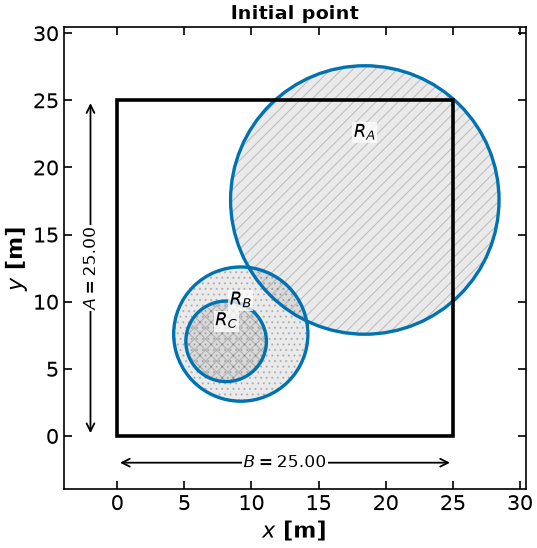

In [10]:
# ---------- EXTRACT, then PLOT --------------------------------------------
# Two functions, deliberately separate -- see the note above.


def extract_circles(m):
    """Pyomo model -> plain Python. After this, nothing needs the model again.

    Arguments:
        m: Pyomo concrete model, solved or merely initialized

    Returns:
        dict with the box dimensions `A` and `B`, the `radii`, and the `centers`
    """
    return {
        "A": pyo.value(m.box_height),
        "B": pyo.value(m.box_width),
        "radii": {i: pyo.value(m.R[i]) for i in m.CIRCLES},
        "centers": {i: (pyo.value(m.x[i]), pyo.value(m.y[i])) for i in m.CIRCLES},
    }


# The house hatch sequence, copied from figures/plots/_house.py as a LITERAL:
# that module is not on disk on Colab, so it must not be imported here. The
# first three entries are three different texture FAMILIES -- lines, dots,
# crosses -- so every pair of circles differs in kind rather than in the sign
# of a slope, which is the cue that survives greyscale printing.
HATCHES = ("///", "...", "xxx", "|||", "---", "\\\\\\")
SHADE_ALPHA = 0.18
OKABE_BLUE = "#0072B2"  # Okabe-Ito; the only color in the figure


def plot_circles(results, start=None, title=None, ax=None, span=None):
    """Draw one arrangement of circles in a box, in the course house style.

    Arguments:
        results: dict from `extract_circles` -- the arrangement to draw solid
        start: optionally, another such dict, drawn dotted and unfilled
            underneath to show where the solver started
        title: text above the panel
        ax: draw into an existing axes instead of creating a figure
        span: force the axis range instead of computing it from the content.
            Pass the same value to several panels when their sizes are meant
            to be compared by eye -- otherwise each panel is scaled to fit and
            two boxes of different size look identical.

    Returns:
        The matplotlib Axes.
    """
    A, B = results["A"], results["B"]
    radii, centers = results["radii"], results["centers"]

    if ax is None:
        _, ax = plt.subplots(figsize=(6, 6))
    hatch_colour = plt.rcParams["hatch.color"]

    # Axis limits from the CONTENT, not from the box: at a loose initial point
    # a circle can stick out well past the walls, and clipping it hides the
    # very thing the picture is being drawn to show.
    extent = []
    for d in (results, start):
        if d is not None:
            extent += [d["A"], d["B"]]
            for i in d["radii"]:
                cx, cy = d["centers"][i]
                extent += [cx + d["radii"][i], cy + d["radii"][i]]
    span = max(extent) if span is None else span
    pad = 0.14 * span

    # Where the solver started: dotted, unfilled, underneath everything else.
    if start is not None:
        ax.add_patch(
            mpatches.Rectangle(
                (0, 0), start["B"], start["A"], facecolor="none",
                edgecolor="0.72", linestyle=":", linewidth=1.5, zorder=1,
            )
        )
        for i in start["radii"]:
            cx, cy = start["centers"][i]
            ax.add_patch(
                mpatches.Circle(
                    (cx, cy), start["radii"][i], facecolor="none",
                    edgecolor="0.72", linestyle=":", linewidth=1.5, zorder=1,
                )
            )

    # The circles: a pale hatch that survives greyscale, a blue outline, and
    # the radius written in the middle. Circle i is labelled R_i, exactly as
    # the model indexes it.
    for k, i in enumerate(radii):
        cx, cy = centers[i]
        ax.add_patch(
            mpatches.Circle(
                (cx, cy), radii[i], facecolor="0.55", alpha=SHADE_ALPHA,
                hatch=HATCHES[k % len(HATCHES)], edgecolor=hatch_colour,
                linewidth=0.0, zorder=2,
            )
        )
        ax.add_patch(
            mpatches.Circle(
                (cx, cy), radii[i], facecolor="none", edgecolor=OKABE_BLUE,
                linewidth=2.4, zorder=3,
            )
        )
        # The label sits half a radius ABOVE the center, not on it. At a loose
        # initial point two circles can be nearly concentric -- the circles
        # overlap, because an initial point need not be feasible -- and two
        # labels on the same spot are unreadable. Offsetting by a fraction of
        # each circle's OWN radius separates them, because the radii differ.
        # The white box keeps the text legible over the hatching.
        ax.annotate(
            f"$R_{{{i}}}$", xy=(cx, cy + 0.5 * radii[i]), fontsize=13,
            ha="center", va="center", zorder=6,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.0),
        )

    # The box, with its two dimensions written on it: A and B ARE the objective.
    ax.add_patch(
        mpatches.Rectangle((0, 0), B, A, facecolor="none", edgecolor="black",
                           linewidth=2.6, zorder=4)
    )
    off = -0.5 * pad
    ax.annotate("", xy=(off, 0), xytext=(off, A),
                arrowprops=dict(arrowstyle="<->", color="black", lw=1.3))
    ax.annotate(f"$A = {A:.2f}$", xy=(off, 0.5 * A), fontsize=12.5, ha="center",
                va="center", rotation=90,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.0))
    ax.annotate("", xy=(0, off), xytext=(B, off),
                arrowprops=dict(arrowstyle="<->", color="black", lw=1.3))
    ax.annotate(f"$B = {B:.2f}$", xy=(0.5 * B, off), fontsize=12.5, ha="center",
                va="center", bbox=dict(facecolor="white", edgecolor="none", pad=1.0))

    ax.set_xlim(-pad, span + 0.5 * pad)
    ax.set_ylim(-pad, span + 0.5 * pad)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("$x$ [m]")
    ax.set_ylabel("$y$ [m]")
    if title:
        ax.set_title(title, fontsize=13.5)
    if start is not None:
        ax.annotate("dotted: where the solver started", xy=(0.02, 0.98),
                    xycoords="axes fraction", fontsize=11, ha="left", va="top",
                    color="0.40")
    return ax


# Keep the initial point: we want to draw it again underneath the solution.
first_start = extract_circles(model)
plot_circles(first_start, title="Initial point")
plt.show()


### Solve and Inspect the Solution

In [11]:
# Specify the solver
solver = pyo.SolverFactory("ipopt")

# Solve the model
results = solver.solve(model, tee=True)
assert pyo.check_optimal_termination(results), (
    f"Solve failed: status={results.solver.status}, "
    f"termination={results.solver.termination_condition}"
)

Ipopt 3.13.2: 

******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit http://projects.coin-or.org/Ipopt

This version of Ipopt was compiled from source code available at
    https://github.com/IDAES/Ipopt as part of the Institute for the Design of
    Advanced Energy Systems Process Systems Engineering Framework (IDAES PSE
    Framework) Copyright (c) 2018-2019. See https://github.com/IDAES/idaes-pse.

This version of Ipopt was compiled using HSL, a collection of Fortran codes
    for large-scale scientific computation.  All technical papers, sales and
    publicity material resulting from use of the HSL codes within IPOPT must
    contain the following acknowledgement:
        HSL, a collection of Fortran codes for large-scale scientific
        computation. See http://

Next, we can inspect the solution. Because Pyomo is a Python extension, we can use Python (for loops, etc.) to programmatically inspect the solution.

Name	Value
box_height 	 19.999999803189603
box_width 	 29.14213541618403
x[A] 	 19.14213551493119
x[B] 	 4.999999951252128
x[C] 	 5.517274811159322
y[A] 	 9.999999901937443
y[B] 	 4.999999953543125
y[C] 	 15.729315741741758


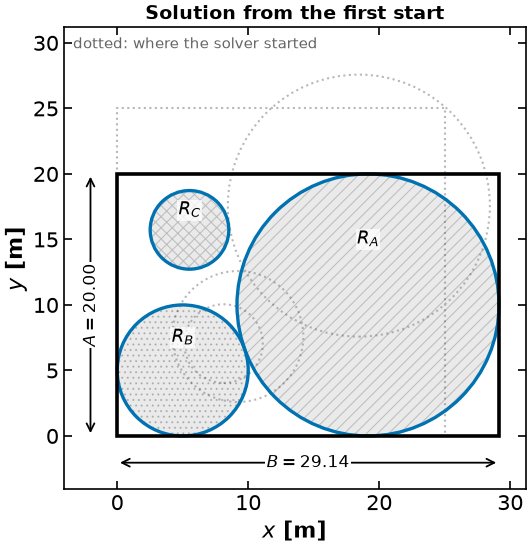

In [12]:
# Print variable values
print("Name\tValue")
for c in model.component_data_objects(pyo.Var):
    print(c.name, "\t", pyo.value(c))

# Plot the solution, with the initial point dotted underneath
plot_circles(
    extract_circles(model), start=first_start, title="Solution from the first start"
)
plt.show()


In [13]:
# Print constraints
for c in model.component_data_objects(pyo.Constraint):
    print(
        c.name,
        "\t",
        pyo.value(c.lower),
        "\t",
        pyo.value(c.body),
        "\t",
        pyo.value(c.upper),
    )

left_x_con[A] 	 10.0 	 19.14213551493119 	 None
left_x_con[B] 	 5.0 	 4.999999951252128 	 None
left_x_con[C] 	 3.0 	 5.517274811159322 	 None
left_y_con[A] 	 10.0 	 9.999999901937443 	 None
left_y_con[B] 	 5.0 	 4.999999953543125 	 None
left_y_con[C] 	 3.0 	 15.729315741741758 	 None
right_x_con[A] 	 None 	 9.87471615587765e-08 	 0.0
right_x_con[B] 	 None 	 -19.1421354649319 	 0.0
right_x_con[C] 	 None 	 -20.624860605024708 	 0.0
right_y_con[A] 	 None 	 9.874784012708915e-08 	 0.0
right_y_con[B] 	 None 	 -9.999999849646478 	 0.0
right_y_con[C] 	 None 	 -1.2706840614478452 	 0.0
no_overlap_con[A,B] 	 225.0 	 224.99999778541928 	 None
no_overlap_con[A,C] 	 169.0 	 218.46188918941948 	 None
no_overlap_con[B,C] 	 64.0 	 115.38579056358046 	 None


### Reinitialize and Resolve

<div class="admonition note"> 
    <p class="title"><b>Activity</b></p>
 Reinitialize the model, plot the initial point, resolve, and plot the solution. Is there more than one solution?
</div>

In [ ]:
# Initialize and print the model

# Add your solution here


In [ ]:
# Plot initial point
# Add your solution here


In [ ]:
# Solve the model
# Add your solution here

In [ ]:
# Plot solution
# Add your solution here


## The Two Local Solutions, Side by Side

The activity above landed on two different boxes from two different starting
arrangements. Let's do that **deliberately**, on the instance the lecture
handout uses --- $\mathbf{R} = (1.0,\ 0.7,\ 0.6)$, "three circles of different sizes" as
Biegler's Example 4.4 puts it --- and build the figure that appears in the
handout.

<div class="admonition note">
<b>Pattern to learn: solve, then extract, then plot.</b> Do not solve and plot in
the same breath. Solve the model, then <b>extract</b> the answer into plain
Python, then <b>plot the extracted results</b>. Three cells, three jobs.

<ul>
<li><b>You can debug the plot without re-solving.</b> Getting three hatched circles,
two dimension arrows and a pair of titles to sit where you want them takes a dozen
attempts. Each one should cost milliseconds, not a fresh call to Ipopt.</li>
<li><b>You can archive the answer.</b> Store the extracted numbers next to your paper
and you can redraw the figure a year later, on a machine with no solver installed,
from the numbers you actually reported.</li>
<li><b>The plot cell cannot lie about the model.</b> If it only ever sees the
extracted results, it cannot quietly recompute something different from what you
solved.</li>
</ul>

In research code, <code>pickle</code> is the quick way to store the extracted
results, and that is what we recommend there. Here the archive is
<b>committed to this repository</b>, so it is written as JSON instead: a pickle in
version control is an unreviewable binary that stops loading the next time a
library is upgraded, and nobody can read its diff.
</div>

In [18]:
# ---------- SOLVE ----------------------------------------------------------
# Nothing is plotted in this cell. This is the only cell below that needs a
# solver.
#
# THE INSTANCE. Biegler prints no numerical radii -- his Figure 4.4 is a sketch
# -- so R = (1.0, 0.7, 0.6) is ours. It was chosen because it has *two*
# certified local minima that are 13.6% apart in perimeter: far enough that the
# two boxes differ visibly on the page, and the radii are visibly unequal, as
# "three circles of different sizes" requires. Other triples give only one, and
# then the picture below is impossible to draw.
lecture_radii = {"1": 1.0, "2": 0.7, "3": 0.6}

# The loose box every run starts from. Biegler's second bullet on p. 68 is
# "change the initial arrangement of the circles and manually shrink the walls
# of the box", so the starting walls are part of the story and get drawn.
BOX_INIT = 4.6

# Two starting arrangements, both feasible, both describable in words.
starts = {
    "strung along the diagonal": {"1": (1.0, 1.0), "2": (2.4, 2.3), "3": (3.4, 3.4)},
    "one circle per corner": {"1": (1.2, 1.2), "2": (3.8, 0.7), "3": (0.7, 3.9)},
}

# ⚠ R_2 SITS SLIGHTLY OFF THE DIAGONAL ON PURPOSE, and that is a lesson rather
# than bookkeeping. This model is symmetric under swapping the two axes
# (A <-> B and x <-> y together). A start with all three centers exactly on the
# line y = x is a fixed point of that symmetry, and Ipopt walks straight down
# it to the symmetric stationary point: a *square* box, perimeter 14.885, which
# is not a local minimum at all. Measured with Pyomo 6.10.1 + Ipopt: centers
# (1.0, 1.0), (2.3, 2.3), (3.4, 3.4) in a box of 4.6 return 14.885, and the
# same start with the box written as 4.599999999999997 returns 11.488. The
# tie-break is being decided by the last bits of the mantissa. Break the
# symmetry yourself; do not leave it to round-off.


def solve_circle_packing(radii, centers, box_init=BOX_INIT):
    """Build, initialize from a named arrangement, and solve. Returns the model."""
    m = create_circle_model(radii)
    m.box_height = box_init
    m.box_width = box_init
    for i, (x0, y0) in centers.items():
        m.x[i] = x0
        m.y[i] = y0
    status = pyo.SolverFactory("ipopt").solve(m)
    assert pyo.check_optimal_termination(status), (
        f"solve failed: {status.solver.termination_condition}"
    )
    return m


def extract_point(m):
    """Pyomo model -> plain Python. After this, nothing needs the model again."""
    return {
        "A": pyo.value(m.box_height),
        "B": pyo.value(m.box_width),
        "perimeter": pyo.value(m.obj),
        "centers": {i: (pyo.value(m.x[i]), pyo.value(m.y[i])) for i in m.CIRCLES},
    }


points = {
    name: extract_point(solve_circle_packing(lecture_radii, centers))
    for name, centers in starts.items()
}

for name, p in points.items():
    print(
        f"start {name:28s} -> A = {p['A']:.4f} m, B = {p['B']:.4f} m, "
        f"perimeter = {p['perimeter']:.4f} m"
    )

names = list(starts)
penalty = 100.0 * (points[names[1]]["perimeter"] / points[names[0]]["perimeter"] - 1.0)
print(f"the two answers differ by {penalty:.1f}% of the better one")

start strung along the diagonal    -> A = 2.5961 m, B = 3.1478 m, perimeter = 11.4880 m
start one circle per corner        -> A = 3.1492 m, B = 3.3733 m, perimeter = 13.0450 m
the two answers differ by 13.6% of the better one


In [19]:
# ---------- RESTRICTED MULTISTART DIAGNOSTIC -------------------------------
# Search the feasible set intersected with a ball about each returned point.
# Finite local solves do not prove that the ball contains no better point.
# A better point in this fixed ball also need not refute local minimality in
# a smaller neighborhood. The exact local certificates are derived below.

DELTA = 0.5
N_TRY = 40


def best_in_ball(radii, z_star, delta=DELTA, n_try=N_TRY, seed=17):
    """Best value found by the finite restricted multistart experiment.

    This is a search diagnostic, not a certified minimum over the ball.
    """
    rng = random.Random(seed)  # seeded: record the sampler for a reproducible diagnostic
    circles = list(radii)
    n = 2 + 2 * len(circles)
    m_units = pyo.units.m
    best = z_star["perimeter"]
    opt = pyo.SolverFactory("ipopt")

    for _ in range(n_try):
        # A point uniform in the ball: random direction, radius ~ U(0,1)^(1/n).
        d = [rng.gauss(0.0, 1.0) for _ in range(n)]
        scale = delta * rng.random() ** (1.0 / n) / sum(v * v for v in d) ** 0.5
        d = [v * scale for v in d]

        m = create_circle_model(radii)
        m.box_height = z_star["A"] + d[0]
        m.box_width = z_star["B"] + d[1]
        for k, i in enumerate(circles):
            m.x[i] = z_star["centers"][i][0] + d[2 + 2 * k]
            m.y[i] = z_star["centers"][i][1] + d[3 + 2 * k]

        # The ball itself, as one extra constraint on the same model.
        m.trust_region = pyo.Constraint(
            expr=(m.box_height - z_star["A"] * m_units) ** 2
            + (m.box_width - z_star["B"] * m_units) ** 2
            + sum(
                (m.x[i] - z_star["centers"][i][0] * m_units) ** 2
                + (m.y[i] - z_star["centers"][i][1] * m_units) ** 2
                for i in circles
            )
            <= delta**2 * m_units**2
        )

        status = opt.solve(m)
        if pyo.check_optimal_termination(status):
            best = min(best, pyo.value(m.obj))
    return best


ball_check = {}
for name, p in points.items():
    ball_check[name] = best_in_ball(lecture_radii, p)
    verdict = "NO LOWER VALUE FOUND" if ball_check[name] > p["perimeter"] - 1e-3 else "LOWER VALUE FOUND IN TEST BALL"
    print(
        f"{name:28s} perimeter {p['perimeter']:.5f}, best in ball of radius "
        f"{DELTA} = {ball_check[name]:.5f}  ->  {verdict}"
    )


strung along the diagonal    perimeter 11.48797, best in ball of radius 0.5 = 11.48797  ->  NO LOWER VALUE FOUND


one circle per corner        perimeter 13.04503, best in ball of radius 0.5 = 13.04503  ->  NO LOWER VALUE FOUND


In [20]:
# ---------- ARCHIVE --------------------------------------------------------
# figures/results/packing-local-solutions.json, committed to the repository.
# `source_tag` points at the model cell above, so scripts/check_results_fresh.py
# can tell you when the model has changed and these numbers have not.
# A no-op on Colab, where there is nothing to commit to.

results = {
    "radii": dict(lecture_radii),
    "box_init": BOX_INIT,
    "delta": DELTA,
    "panels": [
        {
            "name": name,
            "start": {i: list(starts[name][i]) for i in starts[name]},
            "A": points[name]["A"],
            "B": points[name]["B"],
            "perimeter": points[name]["perimeter"],
            "centers": {i: list(points[name]["centers"][i]) for i in lecture_radii},
            "best_in_ball": ball_check[name],
        }
        for name in starts
    ],
}

helper.save_results(
    "packing-local-solutions",
    results,
    notebook="notebooks/1-dev/NLP.ipynb",
    source_tag="handout:circle-packing-model",
    source_cells=[("notebooks/1-dev/NLP.ipynb", t) for t in ['handout:circle-packing-model', 'results:packing-pair-solve', 'results:packing-pair-diagnostic', 'results:packing-pair-extract']],
    description="Biegler Example 4.4 with R = (1.0, 0.7, 0.6), solved twice "
    "from two starting arrangements: two returned arrangements 13.6% apart in "
    "perimeter, with a finite restricted multistart check of radius 0.5.",
    solver="Ipopt via Pyomo",
)


[helper] wrote figures/results/packing-local-solutions.json


In [21]:
# The PLOTTING function: it takes the extracted results, not the Pyomo model.
#
# Everything it needs is in `results`, and nothing else -- no model, no solver.
# That is what lets you re-run this one cell as many times as it takes to get
# the labels where you want them.
#
# This cell is tagged `figure:packing-local-solutions`, which makes it the
# single source of the figure the lecture handout prints. See figures/README.md;
# figures/render_from_notebook.py re-runs exactly this cell against the archived
# JSON when the house style changes. That driver binds `helper` for the cell,
# so this cell may use it without importing anything.

from matplotlib.patches import Circle, Rectangle


def plot_packing_local_solutions(results):
    """Two local solutions of the circle-packing NLP, from two starting guesses.

    WHY THIS FIGURE EXISTS. The model above is nonconvex -- the No Overlap
    constraints are -- so the convexity theorem does not apply and

        "the optimum you find depends on where you start."

    This is the evidence for that sentence, and it is Biegler's own second
    bullet on p. 68. Same model, same solver, same tolerances, two starting
    arrangements, two different answers.

    The restricted multistart experiment is numerical evidence, not a proof.
    The separate exact active-equation/multiplier derivation below gives local
    certificates for the idealized versions of the plotted arrangements.
    Global optimality is a separate question.

    GREYSCALE. The three circles carry three genuinely different hatch families
    -- lines, dots, crosses -- and their own labels, so they are told apart
    without color. The starting arrangement is dotted and unfilled against the
    solid, filled solution: a linestyle contrast, not a color one. The box is
    black in both panels.
    """
    radii = results["radii"]
    panels = results["panels"]
    box0 = results["box_init"]
    circles = list(radii)

    # Hatch literals copied from figures/plots/_house.py, which is NOT on disk
    # on Colab and must not be imported here:
    #   HATCH_CYCLE = ("///", "\\\\\\", "...", "xxx", "|||", "---")
    #   SHADE_ALPHA = 0.18
    # ⚠ HATCH_CYCLE[1], "\\\", is skipped deliberately. Three circles need
    # three textures, and these three spend three different texture FAMILIES,
    # so every pair differs in kind. Restoring [1] puts two of the three in the
    # same family, separated only by the SIGN of the slope -- the most fragile
    # cue here, because the hatch is drawn pale at low alpha inside circles
    # that touch.
    hatches = ("///", "...", "xxx")
    shade_alpha = 0.18
    hatch_colour = plt.rcParams["hatch.color"]
    blue = "#0072B2"  # Okabe-Ito; the solved circles are the only color here
    lim_lo, lim_hi = -0.62, 5.00

    def draw_circles(ax, centers, solution):
        """One arrangement. `solution` toggles solved vs starting guess."""
        for k, i in enumerate(circles):
            x, y = centers[i]
            if solution:
                ax.add_patch(Circle((x, y), radii[i], facecolor="0.55",
                                    alpha=shade_alpha, hatch=hatches[k],
                                    edgecolor=hatch_colour, linewidth=0.0,
                                    zorder=2))
                ax.add_patch(Circle((x, y), radii[i], facecolor="none",
                                    edgecolor=blue, linewidth=2.4, zorder=3))
                ax.annotate("$R_%d$" % (k + 1), xy=(x, y), fontsize=13,
                            ha="center", va="center", zorder=6)
            else:
                ax.add_patch(Circle((x, y), radii[i], facecolor="none",
                                    edgecolor="0.72", linestyle=":",
                                    linewidth=1.5, zorder=1))

    def draw_box(ax, A, B):
        """The enclosing box, with its two dimensions written on it."""
        ax.add_patch(Rectangle((0.0, 0.0), B, A, facecolor="none",
                               edgecolor="black", linewidth=2.6, zorder=4))
        ax.annotate("", xy=(-0.30, 0.0), xytext=(-0.30, A),
                    arrowprops=dict(arrowstyle="<->", color="black", lw=1.3))
        ax.annotate("$A = %.2f$" % A, xy=(-0.30, 0.5 * A), fontsize=12.5,
                    ha="center", va="center", rotation=90,
                    bbox=dict(facecolor="white", edgecolor="none", pad=1.0))
        ax.annotate("", xy=(0.0, -0.30), xytext=(B, -0.30),
                    arrowprops=dict(arrowstyle="<->", color="black", lw=1.3))
        ax.annotate("$B = %.2f$" % B, xy=(0.5 * B, -0.30), fontsize=12.5,
                    ha="center", va="center",
                    bbox=dict(facecolor="white", edgecolor="none", pad=1.0))

    def frame(ax, title):
        """Apply common axes limits, labels, and title to one panel."""
        ax.set_xlim(lim_lo, lim_hi)
        ax.set_ylim(lim_lo, lim_hi)
        ax.set_aspect("equal", adjustable="box")
        ax.set_xlabel("$x$")
        ax.set_title(title, fontsize=13.5)
        ax.set_xticks([0, 1, 2, 3, 4])
        ax.set_yticks([0, 1, 2, 3, 4])

    # ⚠ figsize is set HERE. helper.set_plotting_style() overrides the house
    # default for on-screen readability and render_from_notebook.py does not,
    # so a figure that relied on the default would come out at two different
    # aspect ratios depending on who generated it.
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 5.0))
    axes[0].set_ylabel("$y$")

    penalty = 100.0 * (panels[1]["perimeter"] / panels[0]["perimeter"] - 1.0)
    # ⚠ f-strings, not %-formatting, for these two: scripts/check_greyscale.py
    # blanks any line whose first non-blank character is `%` (it reads it as a
    # Jupyter line magic), so a `% (...)` continuation line makes the whole
    # notebook score "unparseable".
    titles = [
        f"start: {panels[0]['name']}\n$2(A+B) = {panels[0]['perimeter']:.2f}$",
        f"start: {panels[1]['name']}\n$2(A+B) = {panels[1]['perimeter']:.2f}$"
        f"   $(+{penalty:.1f}\\%)$",
    ]

    for ax, panel, title in zip(axes, panels, titles):
        frame(ax, title)
        # The loose box every run starts from: p. 68 is about shrinking these
        # walls, so the walls have to be on the page.
        ax.add_patch(Rectangle((0.0, 0.0), box0, box0, facecolor="none",
                               edgecolor="0.72", linestyle=":", linewidth=1.5,
                               zorder=1))
        draw_circles(ax, panel["start"], solution=False)
        draw_circles(ax, panel["centers"], solution=True)
        draw_box(ax, panel["A"], panel["B"])

    axes[0].annotate("dotted: where the solver started", xy=(0.10, 4.30),
                     fontsize=11.5, ha="left", va="top", color="0.40")

    fig.tight_layout()
    for axis in fig.axes:
        axis.tick_params(colors="black")
        for spine in axis.spines.values():
            spine.set_color("black")
    return fig


fig = plot_packing_local_solutions(results)

# Write media/figures/packing-local-solutions.{png,pdf} -- what the lecture
# handout \includegraphics. A no-op on Colab, where there is no repo to write to.
helper.save_figure(fig, "packing-local-solutions")


[helper] wrote media/figures/packing-local-solutions.png and .pdf


![Two actual returned packing arrangements for radii (1,0.7,0.6).](https://raw.githubusercontent.com/ndcbe/optimization/7c519d44b51cddaa49704c267a4697748da06df1/media/figures/packing-local-solutions.png)


## Multistart

The activity above shows that two starting points can give two different boxes.
That raises the obvious question: *how many* different boxes are there, and how
often does the solver find the best one?

A **multistart** answers that empirically. Solve the same model from many random
initial points, collect the objective values, and look at the distribution. Note
what this does and does not buy you: it raises confidence that you have found the
global solution, but it is **never a certificate**. A global certificate requires a valid bound or a mathematical proof; a global solver is one route, and problem-specific analytic arguments are another.

Two practical points before the code:

1. **Seed the random number generator.** A histogram built from an unseeded
   sampler is a different figure every time the notebook runs, and a number you
   cannot reproduce is a number you cannot defend.
2. **Sample widely enough to matter.** The default `spread=10` used above draws
   the centers from a window smaller than the box itself, and essentially every
   start then lands in the same basin. We widen it below.


In [22]:
def multistart_circle_packing(
    circle_data, n_starts=50, seed=0, spread=40, box_init=40, tee=False
):
    """Solve the circle packing model from many random initial points

    Arguments:
        circle_data: dictionary with keys=circle name and value=radius (float)
        n_starts: number of random initializations (int)
        seed: seed for the random number generator, so the result reproduces
        spread: width of the uniform window the centers are drawn from
        box_init: initial value for both box dimensions
        tee: print solver output

    Returns:
        results: pandas DataFrame, one row per start, with the objective and
            the box dimensions (NaN if that start did not solve)
        arrangements: dict keyed by start, each holding the extracted `start`
            point and the extracted `solution` (None if that start failed).
            This is what lets us go back and LOOK at a chosen solution; the
            DataFrame alone records that the local solutions differ, not what
            any of them looks like.
    """
    # Reproducibility. Reseeding here means this cell gives the same answer no
    # matter which other cells were run first.
    random.seed(seed)

    solver = pyo.SolverFactory("ipopt")

    rows = []
    arrangements = {}
    for k in range(n_starts):
        m = create_circle_model(circle_data)
        initialize_circle_model(
            m, height_init=box_init, width_init=box_init, spread=spread
        )
        # Keep the initial point BEFORE solving -- afterwards it is gone, and
        # for a nonconvex model the initial point is half of what makes an
        # answer reportable.
        # ⚠ Extracting it draws no random numbers, so the sampling sequence,
        # and therefore every number this section prints, is unchanged.
        start_point = extract_circles(m)

        res = solver.solve(m, tee=tee)
        if pyo.check_optimal_termination(res):
            arrangements[k] = {"start": start_point, "solution": extract_circles(m)}
            rows.append(
                {
                    "start": k,
                    "perimeter": pyo.value(m.obj),
                    "A": pyo.value(m.box_height),
                    "B": pyo.value(m.box_width),
                }
            )
        else:
            arrangements[k] = {"start": start_point, "solution": None}
            rows.append(
                {"start": k, "perimeter": float("nan"), "A": float("nan"),
                 "B": float("nan")}
            )

    return pd.DataFrame(rows), arrangements


# The multistart experiment, named ONCE. The archive cell below records these
# four numbers alongside the perimeters, and a literal repeated in two cells is
# a literal that will eventually disagree with itself.
MS_STARTS = 50
MS_SEED = 0
MS_SPREAD = 40
MS_BOX_INIT = 40

ms, ms_points = multistart_circle_packing(
    circle_data,
    n_starts=MS_STARTS,
    seed=MS_SEED,
    spread=MS_SPREAD,
    box_init=MS_BOX_INIT,
)

n_failed = int(ms["perimeter"].isna().sum())
print(f"{len(ms)} starts, {n_failed} failed to converge")
print(f"Best perimeter found: {ms['perimeter'].min():.4f}")


50 starts, 0 failed to converge
Best perimeter found: 98.2843


In [23]:
# How many distinct local solutions did we land on?
counts = (
    ms["perimeter"]
    .round(3)
    .value_counts()
    .rename_axis("perimeter")
    .reset_index(name="number of starts")
    .sort_values("perimeter")
    .reset_index(drop=True)
)
counts["fraction"] = counts["number of starts"] / len(ms)
display(counts)


,perimeter,number of starts,fraction
0,98.284,42,0.84
1,101.977,3,0.06
2,106.193,5,0.10


In [24]:
# ---------- EXTRACT + ARCHIVE ---------------------------------------------
# pandas -> plain Python, then figures/results/packing-multistart-histogram.json,
# committed to the repository. After this cell nothing below touches `ms`, a
# Pyomo model, or a solver: the plotting cell reads `results` and nothing else,
# so the histogram can be redrawn as many times as it takes without paying for
# fifty solves again.
#
# `source_tag` points at the model cell above, so scripts/check_results_fresh.py
# can tell you when the model has changed and these numbers have not. Writing is
# a no-op on Colab, where there is nothing to commit to.
#
# ⚠ WHAT IS ARCHIVED IS THE FIFTY PERIMETERS, NOT THE HISTOGRAM'S BIN HEIGHTS.
# The number of bins is a plotting decision and belongs in the plot cell;
# freezing the bins here would make a *style* change to this figure impossible
# without re-solving, and avoiding exactly that is the archive's only job.
# A start that failed to converge is stored as `null` rather than dropped, so
# the archive still records how many starts were run.

results = {
    "radii": dict(circle_data),
    "n_starts": MS_STARTS,
    "seed": MS_SEED,
    "spread": MS_SPREAD,
    "box_init": MS_BOX_INIT,
    "perimeters": [None if pd.isna(v) else float(v) for v in ms["perimeter"]],
    "best": float(ms["perimeter"].min()),
    # The `counts` table printed above: one row per distinct local solution.
    "spikes": helper.table(counts),
}

helper.save_results(
    "packing-multistart-histogram",
    results,
    notebook="notebooks/1-dev/NLP.ipynb",
    source_tag="handout:circle-packing-model",
    source_cells=[("notebooks/1-dev/NLP.ipynb", t) for t in ['handout:circle-packing-model', 'results:packing-initializer', 'results:packing-notebook-data', 'results:packing-multistart-solve', 'results:packing-multistart-count', 'results:packing-multistart-extract']],
    description=(
        "Circle packing on the notebook's instance R = (10, 5, 3): perimeters "
        "from 50 random starts, seed 0, centers drawn uniformly from a window "
        "of width 40. The perimeters fall in three returned objective groups "
        "rather than a spread."
    ),
    solver="Ipopt via Pyomo",
)


[helper] wrote figures/results/packing-multistart-histogram.json


In [25]:
# The PLOTTING function: it takes the extracted results, not the Pyomo model.
#
# This cell is tagged `figure:packing-multistart-histogram`, which makes it the
# single source of the histogram the lecture handout prints. See
# figures/README.md; figures/render_from_notebook.py re-runs exactly this cell
# against the archived JSON when the house style changes, so there is no second
# copy of the plotting code anywhere. That driver binds `helper` for the cell,
# so this cell may use it without importing anything.


def plot_packing_multistart_histogram(results):
    """Perimeters from many random starts: a few sharp spikes, not a spread.

    WHY THIS FIGURE EXISTS. The two-panel figure earlier in this notebook shows
    that *two* starting arrangements give two different boxes. It cannot show
    how many different boxes there are, or how often the solver finds the best
    one. This does: every start is one sample, and the samples pile up on a
    handful of values because Ipopt converges to a small number of distinct
    local solutions.

    ⚠ THIS IS A LARGER INSTANCE THAN THE TWO-PANEL FIGURE, on purpose --
    R = (10, 5, 3) here against R = (1.0, 0.7, 0.6) there -- so the perimeters
    are around 98 rather than around 11. The two figures are two different
    experiments and must not be read as one; the axis label and the title both
    carry the instance so a reader cannot mistake them.

    THE COUNTS ARE PRINTED, and that is reproducible only because the seed is.
    An unseeded sampler gives a different count every run; with the seed quoted,
    "42 of 50" is a number someone else can obtain. The *best value* is far more
    robust than the count -- it is the same for every seed tried, while the
    split between the spikes is not -- so the best value is drawn as a rule
    across the whole axes and the counts are annotations on the bars.

    GREYSCALE. There is one data series and it is achromatic: grey bars with
    black edges. The only color is the vermillion rule at the best value
    found, which is also DASHED, so it is identified without color.
    """
    perimeters = [p for p in results["perimeters"] if p is not None]
    n_starts = results["n_starts"]
    seed = results["seed"]
    best = results["best"]
    radii = results["radii"]

    # ⚠ figsize is set HERE. helper.set_plotting_style() overrides the house
    # default for on-screen readability and render_from_notebook.py does not,
    # so a figure that relied on the default would come out at two different
    # aspect ratios depending on who generated it.
    fig, ax = plt.subplots(figsize=(7.4, 4.4))

    heights, edges, _ = ax.hist(perimeters, bins=30, color="0.60",
                                edgecolor="black", linewidth=1.0, zorder=2)

    # Okabe-Ito vermillion, from figures/dowling.mplstyle. Plain "red" is not in
    # the palette: it is the color a red-green color-blind reader cannot
    # separate from the black bar edges, and it prints as almost the same grey.
    ax.axvline(best, color="#D55E00", linestyle="--", linewidth=2.4, zorder=3,
               label=f"best found = {best:.3f} m")

    # One annotation per spike, read off the archived counts table rather than
    # typed in: the number of spikes depends on the seed and the sampler, so a
    # hard-coded three would break by drawing the wrong labels rather than by
    # raising an error.
    cols = results["spikes"]["columns"]
    ip, ic = cols.index("perimeter"), cols.index("number of starts")
    rows = results["spikes"]["rows"]

    # ⚠ EACH LABEL IS PLACED OVER ITS BAR, NOT OVER ITS PERIMETER. A spike sits
    # somewhere inside a bin, and a bin here is about 0.26 m wide, so a label
    # centered on the perimeter itself hangs off the side of the bar it belongs
    # to -- and for the leftmost spike, which is the whole point of the figure,
    # off the left edge of the axes entirely. Found by rendering and looking.
    for row in rows:
        k = min(range(len(heights)), key=lambda j: abs(row[ip] - edges[j]))
        k = min(k, len(heights) - 1)
        if row[ip] < edges[k]:
            k = max(k - 1, 0)
        ax.annotate(
            f"{int(row[ic])} of {n_starts}",
            xy=(0.5 * (edges[k] + edges[k + 1]), heights[k]),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=11.5,
            zorder=4,
            # The label over the tallest bar is crossed by the dashed rule at
            # the best value; a white patch behind the text keeps both legible
            # without moving either off the thing it labels.
            bbox=dict(facecolor="white", edgecolor="none", pad=0.8),
        )

    # Headroom above the tallest bar for its label, and a margin at each end so
    # the outer two labels are not clipped by the frame.
    ax.set_ylim(0, 1.17 * max(heights))
    pad = 0.05 * (edges[-1] - edges[0])
    ax.set_xlim(edges[0] - pad, edges[-1] + pad)

    r_text = ", ".join(f"{radii[i]:g}" for i in radii)
    ax.set_xlabel("Perimeter of the enclosing box, $2(A + B)$ [m]")
    ax.set_ylabel("Number of starts")
    ax.set_title(
        f"{n_starts} random starts, seed {seed};  $R = ({r_text})$", fontsize=13.5
    )
    ax.legend(loc="upper right")

    fig.tight_layout()
    for axis in fig.axes:
        axis.tick_params(colors="black")
        for spine in axis.spines.values():
            spine.set_color("black")
    return fig


fig = plot_packing_multistart_histogram(results)

# Write media/figures/packing-multistart-histogram.{png,pdf} -- what the lecture
# handout \includegraphics. A no-op on Colab, where there is no repo to write to.
helper.save_figure(fig, "packing-multistart-histogram")


[helper] wrote media/figures/packing-multistart-histogram.png and .pdf


![50-start packing results for radii (10,5,3), with counts42,3,5.](https://raw.githubusercontent.com/ndcbe/optimization/7c519d44b51cddaa49704c267a4697748da06df1/media/figures/packing-multistart-histogram.png)


In [26]:
# Which start gave the best box?
best_start = int(ms["perimeter"].idxmin())
print(f"Best start: #{best_start}")
print(f"  perimeter = {ms.loc[best_start, 'perimeter']:.4f} m")
print(f"  A = {ms.loc[best_start, 'A']:.4f} m, B = {ms.loc[best_start, 'B']:.4f} m")


Best start: #41
  perimeter = 98.2843 m
  A = 20.0000 m, B = 29.1421 m


### What do the objective groups look like?

The histogram groups returned objective values after rounding; it does not certify local minimality or establish that every basin has been found. Draw one recorded arrangement per observed group. The code obtains the groups from `counts`, rather than assuming in advance how many there are.


perimeter 98.284 m  <-  42 of 50 starts, e.g. start #0
perimeter 101.977 m  <-   3 of 50 starts, e.g. start #12
perimeter 106.193 m  <-   5 of 50 starts, e.g. start #20


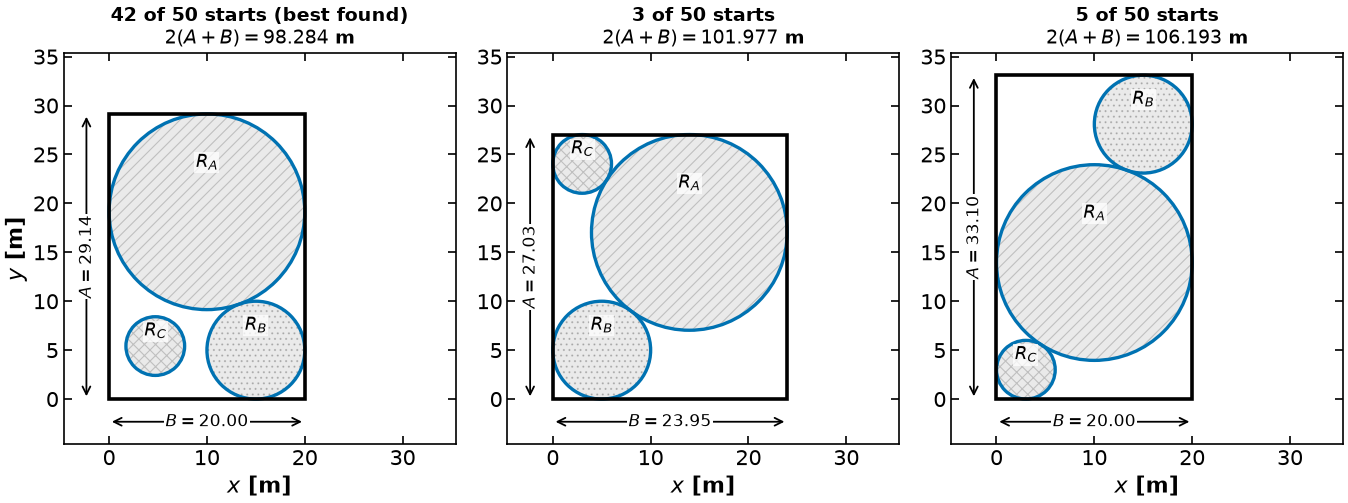

In [27]:
# One representative start per spike, chosen programmatically from `counts`.
spikes = ms["perimeter"].round(3)
representatives = [
    {
        "perimeter": p,
        "n_starts": int(n),
        # The first start that landed on this spike. Any member would do; the
        # first is the reproducible choice.
        "start": int(spikes[spikes == p].index[0]),
    }
    for p, n in zip(counts["perimeter"], counts["number of starts"])
]

for r in representatives:
    print(
        f"perimeter {r['perimeter']:.3f} m  <-  {r['n_starts']:2d} of {len(ms)} "
        f"starts, e.g. start #{r['start']}"
    )

# One shared scale across the panels, so the boxes can be compared by eye.
# Without this each panel is fitted to its own contents and the biggest box
# looks the same size as the smallest.
shared_span = max(
    max(ms_points[r["start"]]["solution"]["A"], ms_points[r["start"]]["solution"]["B"])
    for r in representatives
)

fig, axes = plt.subplots(
    1, len(representatives), figsize=(4.6 * len(representatives), 5.2), squeeze=False
)
for ax, r in zip(axes[0], representatives):
    best = " (best found)" if r is representatives[0] else ""
    plot_circles(
        ms_points[r["start"]]["solution"],
        title=(
            f"{r['n_starts']} of {len(ms)} starts{best}\n"
            f"$2(A+B) = {r['perimeter']:.3f}$ m"
        ),
        ax=ax,
        span=shared_span,
    )
    if ax is not axes[0][0]:
        ax.set_ylabel("")
fig.tight_layout()
plt.show()


The returned arrangements place circles against different walls and corners. A plot and a solver termination status alone do not prove that no nearby feasible arrangement improves them. The exact certificate later in this guide concerns the separate small instance with radii $(1,0.7,0.6)$, not these larger-instance histogram representatives.

Starting points are omitted from these panels because the sampler's width-40 window would force the solved arrangements into a small corner of a shared scale. The earlier two-panel figure includes its deliberately chosen starts.


The recorded 50-start experiment has three objective groups, with counts 42, 3, and 5. Most starts reach the smallest recorded perimeter, but several do not. The two figures use different radius data: $(10,5,3)$ for this histogram and $(1,0.7,0.6)$ for the earlier pair.

Report the instance, seed, sampler, tolerances and successful/failed solve counts with the observed distribution. Changing the seed or sampling window can change both group counts and what is found. Even unanimous agreement would be numerical search evidence, not a global certificate. Compare candidates with a valid bound or a separate proof when certification matters.


<div class="admonition note">
<p class="title"><b>Activity</b></p>
 Change the seed and re-run the multistart. Does the best perimeter
change? Does the <i>fraction</i> of starts that find it change? Which of those two
would you be willing to put in a report?
</div>


## Take Away Messages
* Nonlinear programs may be nonconvex. For nonconvex problems, there often exist many local optima that are not also global optima.
* We will learn how to mathematically define convexity and analyze this property.
* Initialization is really important in optimization problems with nonlinear objectives or constraints!
* There are specialized solvers for linear programs, quadratic programs, and convex programs. In this class, we will focus on more general algorithms for (non)convex nonlinear programs including the algorithms used by the `ipopt` solver.

(ci-ref-packing)=
## Reference: local certificates for the two packing arrangements

The restricted multistart cell reports what it found in a ball, not a certified minimum over that ball. No finite collection of local solves proves that no better feasible point exists there. A better point at a fixed distance also need not disprove a local minimum in a smaller neighborhood.

Here is separate mathematical evidence for the two plotted arrangements with radii $(1,0.7,0.6)$. Use numerical coordinate values in metres and the matching constraint scalings. Let $A$ be box height, $B$ width, and $q_{ij}=(R_i+R_j)^2-\|\mathbf c_i-\mathbf c_j\|^2\le0$. The objective is $2(A+B)$.

### One circle per corner

The six active box bounds place the centers at

$$\mathbf c_1=(1,1),\qquad
\mathbf c_2=(B-0.7,0.7),\qquad
\mathbf c_3=(0.6,A-0.6).$$

Contacts $q_{12}=q_{13}=0$ give

$$B=1.7+\sqrt{2.8},\qquad A=1.6+\sqrt{2.4}.$$

The remaining bounds are slack. The squared separation of circles 2 and 3 is
$(0.4+\sqrt{2.8})^2+(0.3+\sqrt{2.4})^2>5.2>1.3^2$, so they do not overlap.

Let $s=\sqrt{2.8}$, $t=\sqrt{2.4}$. Positive multipliers for contacts $q_{12},q_{13}$ are $1/s,1/t$. In the order lower-$x_1$, lower-$y_1$, lower-$y_2$, upper-$x_2$, lower-$x_3$, upper-$y_3$, the bound multipliers are

$$2-\frac{0.8}{t},\quad2-\frac{0.6}{s},\quad
\frac{0.6}{s},\quad2,\quad\frac{0.8}{t},\quad2.$$

Each is positive; substitution into the eight stationarity equations verifies gradient balance. The six bound equations eliminate six coordinates; the remaining contact equations have nonzero derivatives $2s,2t$ in $B,A$. Thus the eight active gradients have rank eight.

### Strung along the diagonal

Write $c=\sqrt{1.68}$, $A=1.3+c$, $B=1.7+s$, and
$t=(0.1s+1.01)/c$. The five active bounds place

$$\mathbf c_1=(1,0.7+t),\quad
\mathbf c_2=(1+s,0.7),\quad
\mathbf c_3=(1.1+s,0.7+c).$$

The contact of circles 2 and 3 gives $0.1^2+c^2=1.3^2$. The other two contacts are
$s^2+t^2=1.7^2$ and $(s+0.1)^2+(t-c)^2=1.6^2$. Subtraction gives the displayed formula for $t$, and substitution gives

$$1.69s^2+0.202s-3.8351=0.$$

Use its positive root. Direct rational bounds give
$1.44<s<1.46$, $1.29<c<1.30$, $0.886<t<0.901$.
The delicate inactive top bound for circle 1 has slack

$$A-1-y_1=c-t-0.4
=\frac{0.67-0.1s}{c}-0.4
>\frac{0.524}{1.30}-0.4>0.$$

All other inactive bounds are plainly slack from those intervals.

Put $D=sc+0.1t>0$. Contact multipliers satisfying the center force balances are

$$a=\frac{c-t}{D},\qquad b=\frac{t}{D},\qquad
d=\frac{1-(c-t)b}{c}$$

for $q_{12},q_{13},q_{23}$. The lower-$x_1$, lower-$y_2$ and upper-$y_3$ bound multipliers are all 2. The two right-wall multipliers are

$$\mu_2=2sa-0.2d,\qquad
\mu_3=2(s+0.1)b+0.2d,\qquad\mu_2+\mu_3=2.$$

The intervals prove $a,b,d>0$. They also give
$\mu_2>2(1.44)(0.389)/1.9881-0.2/1.29>0.40$;
$\mu_3$ is a sum of positive terms. After eliminating the five active bounds, the 2–3 contact fixes $A$ with derivative $2c$. The remaining two-contact Jacobian in $(s,t)$ has determinant $-4(sc+0.1t)\ne0$. Again the eight active gradients have full rank.

### What the local certificate establishes

For each exact feasible arrangement, KKT holds with strictly positive multipliers on eight independent active constraints. A critical direction must be tangent to all eight, so it is zero. The second-order sufficient condition is therefore vacuous on nonzero critical directions, and the point is a **strict local minimum**. This applies to the exact algebraic arrangement; the plotted Ipopt coordinates approximate it within solver tolerance. Neither local certificate proves global optimality.

The numerical active-Jacobian checks give minimum multipliers approximately 0.2061 and 0.3586. Refining the active equations gives residuals below $10^{-15}$, with perimeters approximately 11.4879722 and 13.0450268. The original archived solver values differ only at solver accuracy and remain the values used by the shared figure.

Source for the certificate implication: Biegler (2010), Theorem 4.18, p.81; the packing model is Example 4.4, pp.67–68. The exact active-equation and multiplier derivation above is independently supplied for this course's chosen radii.


(continuous-convexity)=
## Reference: convex sets, objectives and certificates

A set $S\subset\mathbb R^n$ is convex if $\theta\mathbf x+(1-\theta)\mathbf y\in S$ for every $\mathbf x,\mathbf y\in S$ and $\theta\in[0,1]$. An affine hyperplane $\{\mathbf x:\mathbf a^T\mathbf x=b\}$ and a halfspace $\{\mathbf x:\mathbf a^T\mathbf x\le b\}$ are convex: applying $\mathbf a^T$ to a convex combination preserves equality or the inequality. Intersections of convex sets are convex because the segment belongs to every set. Nonnegative bounds are halfspaces, so polyhedra defined by linear equalities, inequalities and bounds are convex.

A function $f:D\to\mathbb R$ on a convex domain is convex if

$$f(\theta\mathbf x+(1-\theta)\mathbf y)\le\theta f(\mathbf x)+(1-\theta)f(\mathbf y).$$

Strict convexity uses a strict inequality for distinct $\mathbf x,\mathbf y$ and $0<\theta<1$. For $f\in C^2(D)$ on an **open convex** domain, convexity is equivalent to $\nabla^2 f(\mathbf x)\succeq0$ everywhere. Positive definiteness everywhere is sufficient for strict convexity, not necessary: $x^4$ is strictly convex although $f''(0)=0$. Positive definiteness point by point is not a uniform strong-convexity lower bound.

For a convex objective minimized over a convex feasible set, every local minimum is global. Strict convexity gives at most one minimizer if one exists. A linear objective with linear constraints is an LP; a quadratic objective with a positive-semidefinite Hessian and convex linear constraints is a convex QP. Smooth nonlinear formulas alone say nothing about convexity. Portfolio optimization is the homework application: its [native guide](Portfolio-Optimization.ipynb) retains the complete model, covariance data and frontier calculation.

The [unconstrained-optimality guide](../6/Optimality.ipynb) gives the full chord contradiction, strict uniqueness argument and local derivative tests. A termination flag is numerical evidence governed by feasibility and tolerances, not a proof supplied by the solver's name.

Sources: Biegler (2010), Theorem 4.3, p.65; Chapter 2, pp.27–30, with the errata. The distinct-point strictness qualification and $x^4$ counterexample prevent misreading positive definiteness as an equivalence.


![Convex functions lie below endpoint chords; strict convexity does not require positive Hessian at every point.](https://raw.githubusercontent.com/ndcbe/optimization/7c519d44b51cddaa49704c267a4697748da06df1/media/figures/co-convex-functions.png)

**Nonconvexity of the full packing feasible set.** For the small radii $(1,0.7,0.6)$, fix $A=B=10$. The center tuples $((2,2),(8,2),(5,8))$ and $((8,2),(2,2),(5,8))$ are both feasible. Their arithmetic midpoint places both circles 1 and 2 at $(5,2)$, violating their positive separation requirement. This checks the full model, not only one nonlinear row in isolation.


(continuous-workflow)=
## Reference: from a mathematical model to a computation

The five modeling objects are sets, parameters, variables, objective and constraints. First define the physical decision and units. Write a mathematical model and count its declared components. Compute with a solver, inspect feasibility and the returned objective, and analyze what the answer means for the original decision. These stages feed back: analysis can reveal missing capacity or uncertain data; a failed solve can reveal a scaling or initialization problem; a revised model can require new measurements. The approved handout workflow illustration accompanies this same procedure.

`ConcreteModel()` creates the component container. An indexed `Set` provides the identifiers used by `Param`, `Var`, and indexed constraint rules. A `Param` initializer loads numerical data; use `mutable=True` when a parameter must change after construction. A solve uses one active objective. Rebuild or update any dependent bounds when changing data. A `Var` initializer supplies a guess rather than a fixed decision. `domain=` and `bounds=` define admissible values. An objective supplies its expression and minimization/maximization sense. A decorated constraint function receives the model as its first argument and returns a symbolic relation, not a Python truth value. Indexing a rule makes one row for each permitted index. A scalar declaration makes one row.

The circle builder uses `Constraint.Skip` when $i\ge j$. This excludes reversed duplicates **and self-pairs**: $i=j$ would impose $0\ge(2R_i)^2$, impossible for positive radii. Repeating a reversed active pair can create dependent active gradients and violate a constraint qualification; it does not change the feasible set. Do not infer that every redundant inactive row invalidates every algorithm.

Assign coordinate and box guesses explicitly before solving. An uninitialized Pyomo variable stores `None`; its domain does not choose a guess. The solver interface and solver may then choose or push a bound-interior starting point. Record both the supplied initialization and relevant solver options. `assert_units_consistent(model)` checks dimensional expressions when it is called; it does not certify a feasible or optimal solution. Fat fractions and some ratios are dimensionless, so a physically incorrect equation can still pass a units check.

After solving, extract plain numbers before plotting or archiving. This separates the model/solve from display choices and lets the same returned data support a table, figure, and later diagnostic. Keep the solver status, tolerances and feasibility checks with the numbers. The full circle builder above remains the computational owner of its shorter printed listing.

Official variable reference: [Pyomo variables](https://pyomo.readthedocs.io/en/stable/explanation/modeling/math_programming/variables.html).

**Transfer activity.** Name a continuous decision in your field, one uncertain input, and a constraint whose geometry you would check. For example, a reactor temperature is chosen, kinetics are estimated, and conversion/safety constraints need a convexity check.


(continuous-ad-sparsity)=
## Reference: derivative cost and sparse structure

For a scalar $f:\mathbb R^n\to\mathbb R$, a dense one-sided finite-difference gradient uses a baseline evaluation and one perturbed evaluation per component: $n+1$ evaluations without additional reuse. A central formula uses two per component. The step controls truncation error versus cancellation/roundoff; finite differences do not inherently make a model ill-conditioned.

Automatic differentiation applies the chain rule to the computational graph, rather than differencing nearby function values. Reverse mode computes a scalar objective's full gradient at a small constant multiple of its evaluation cost, with a storage/recomputation tradeoff. This statement does not give dimension-independent cost for every vector Jacobian or Hessian. Floating-point errors and nonsmooth operations still need attention. See Nocedal and Wright (2006), pp.195–196, 204, and 210.

For a circle-packing Jacobian, each of the $4n$ containment rows involves one or two variables: together they contribute $6n$ structural entries. Each of the $\binom n2$ separation rows involves four center coordinates. Thus the structural count is $6n+4\binom n2=2n^2+4n$. For three circles this is 30 entries in a $15\times8$ array with 120 possible positions. Particular coordinates can make a structurally possible derivative numerically zero.

The hourly battery model with $N=8,760$ periods and variables $(c_t,d_t,E_t)$ has $3N=26,280$ variables and $N+1=8,761$ equality rows, including the terminal condition. The first balance has three entries, the other $N-1$ balances four each, and the terminal row one: $3+4(N-1)+1=4N=35,040$ structural Jacobian entries. A dense representation would reserve 230,239,080 positions. Sparse storage and factorization exploit the actual dependency pattern; a low nonzero count alone is not a runtime guarantee.


(continuous-absolute-values)=
## Reference: exact absolute-value formulations

For $\min_{-10\le x\le10}(|x|+\tfrac12x)$, the kink at zero prevents a classical derivative there, although the function is convex and zero is its unique minimizer. Differentiability and convexity are different properties.

**Smooth complementarity formulation.** Introduce $x=x^+-x^-$, $x^+,x^-\ge0$, and $x^+x^-=0$. Exactly one sign part can be positive, so $x^++x^-=|x|$. Minimize $x^++x^-+\tfrac12(x^+-x^-)$ and retain $-10\le x^+-x^-\le10$. The algebra is smooth, but complementarity creates nonconvexity: $(x^+,x^-)=(1,0)$ and $(0,1)$ are feasible while their midpoint is not. At their intersection, the complementarity gradient is zero; standard regularity assumptions need separate care.

**Binary formulation.** With $b\in\{0,1\}$, impose $0\le x^+\le Mb$, $0\le x^-\le M(1-b)$, $x=x^+-x^-$, and the original bounds. Choose a valid $M\ge10$ for this bounded domain; a smaller value removes legitimate $x$ values, while an unnecessarily large value weakens continuous relaxations. The binary chooses the nonzero sign part. Minimize $x^++x^-+\tfrac12(x^+-x^-)$.

**LP epigraph formulation.** Introduce $t\ge x$ and $t\ge-x$, keep $-10\le x\le10$, and minimize $t+\tfrac12x$. For any feasible $x$, the smallest possible $t$ is $\max(x,-x)=|x|$; a positive objective coefficient on $t$ forces equality at an optimum. A nonpositive coefficient or unrelated use of $t$ requires a new argument. This same epigraph construction works for a convex piecewise-linear maximum of finitely many affine functions. It uses no binary variable and avoids imposing the nonconvex equality $t=|x|$.

The full original diet data/model remain in [Linear Programming](LP.ipynb). These absolute-value alternatives illustrate why a nonlinear-looking formula and the best available optimization formulation need not have the same classification.


![The nonsmooth objective and the nonconvex complementarity lift.](https://raw.githubusercontent.com/ndcbe/optimization/7c519d44b51cddaa49704c267a4697748da06df1/media/figures/co-absolute-value.png)


![Lowering the epigraph variable at fixed x preserves feasibility and improves the positive-coefficient objective.](https://raw.githubusercontent.com/ndcbe/optimization/7c519d44b51cddaa49704c267a4697748da06df1/media/figures/co-absolute-epigraph.png)
